# Model Evaluation and Comparison for Phishing URL Detection

## 1. Introduction

Model evaluation is an important stage in a machine learning project because it determines how well the trained models perform on previously unseen data.

In the previous notebooks, baseline models were trained and hyperparameters were optimized using cross-validation on the training data.

This notebook evaluates the tuned models on the independent test dataset and compares their classification performance.

## 2. Objectives

The main objectives of this notebook are:

- Load the selected feature dataset.
- Recreate the leakage-free URL-group train-test split.
- Load the tuned machine learning models.
- Generate predictions on the unseen test dataset.
- Calculate classification metrics.
- Generate confusion matrices.
- Generate classification reports.
- Analyze ROC curves and ROC-AUC.
- Compare the performance of the tuned models.
- Identify the model performance characteristics relevant to the phishing detection task.

## 3. Models Evaluated

The following tuned models will be evaluated:

1. Logistic Regression
2. Decision Tree
3. Random Forest

These models were tuned in the previous notebook using cross-validation.

## 4. Evaluation Metrics

The following metrics will be calculated:

### Accuracy

Measures the proportion of correctly classified observations.

### Precision

Measures the proportion of observations predicted as legitimate that are actually legitimate.

### Recall

Measures the proportion of actual legitimate observations correctly identified by the model.

### F1-Score

The harmonic mean of precision and recall.

### ROC-AUC

Measures the model's ability to distinguish between the two target classes across different classification thresholds.

## 5. Confusion Matrix

A confusion matrix will be used to examine:

- True Positives
- True Negatives
- False Positives
- False Negatives

The confusion matrix provides a detailed view of the types of classification errors produced by each model.

## 6. Test Dataset

The test dataset was not used during feature selection or hyperparameter tuning.

The URL-group splitting strategy is maintained so that the same URL does not appear in both training and testing datasets.

This provides an independent evaluation of the tuned models.

## 7. Model Comparison

The models will be compared using their measured test-set performance.

The comparison will report the actual experimental values rather than assigning subjective ratings.

## 8. Expected Outcome

At the end of this notebook, the project will contain:

- Complete evaluation metrics
- Confusion matrices
- Classification reports
- ROC curves
- A model comparison table
- Saved evaluation results and figures

These results will be used in the final results, discussion, and prediction stages.

In [1]:
import pandas as pd

df = pd.read_csv("../dataset/PhiUSIIL_Selected_Features.csv")

print("READY")
print(df.shape)

READY
(235795, 41)


In [2]:
# Separate features and target

X = df.drop(columns=["label"])
y = df["label"]

print("DATA PREPARED")
print("=" * 50)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", X.shape[1])

DATA PREPARED
X shape: (235795, 40)
y shape: (235795,)
Number of features: 40


In [3]:
# Recreate the leakage-free URL-group train/test split

from sklearn.model_selection import train_test_split

print("CREATING URL-GROUP TRAIN/TEST SPLIT")
print("=" * 50)

# Load only URL and label columns
url_data = pd.read_csv(
    "../dataset/PhiUSIIL_Engineered_Features.csv",
    usecols=["URL", "label"]
)

# Create unique URL groups
url_groups = url_data.drop_duplicates("URL")

# Split unique URLs
train_urls, test_urls = train_test_split(
    url_groups,
    test_size=0.20,
    random_state=42,
    stratify=url_groups["label"]
)

# Create URL sets
train_url_set = set(train_urls["URL"])
test_url_set = set(test_urls["URL"])

# Create masks
train_mask = url_data["URL"].isin(train_url_set)
test_mask = url_data["URL"].isin(test_url_set)

# Create train/test data
X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining features:", X_train.shape[1])

print("\nURL overlap:",
      len(train_url_set.intersection(test_url_set)))

if len(train_url_set.intersection(test_url_set)) == 0:
    print("✅ No URL leakage detected.")

CREATING URL-GROUP TRAIN/TEST SPLIT
Training records: 188644
Testing records: 47151

Training features: 40

URL overlap: 0
✅ No URL leakage detected.


In [6]:
# Check which tuned model files are available

import os
import joblib

models_folder = "../models"

print("CHECKING SAVED MODEL FILES")
print("=" * 50)

files = os.listdir(models_folder)

for file in files:
    print(file)

print("\n" + "=" * 50)

required_files = [
    "tuning_feature_scaler.pkl",
    "logistic_regression_tuned.pkl",
    "decision_tree_tuned.pkl",
    "random_forest_tuned.pkl"
]

print("Required tuned files:")

for file in required_files:
    if file in files:
        print("✅", file)
    else:
        print("❌", file, "NOT FOUND")

CHECKING SAVED MODEL FILES
decision_tree_baseline.pkl
decision_tree_tuned.pkl
feature_scaler.pkl
logistic_regression_baseline.pkl
logistic_regression_tuned.pkl
random_forest_baseline.pkl
tuning_feature_scaler.pkl

Required tuned files:
✅ tuning_feature_scaler.pkl
✅ logistic_regression_tuned.pkl
✅ decision_tree_tuned.pkl
❌ random_forest_tuned.pkl NOT FOUND


In [3]:
# Create and save the missing tuned Random Forest model

import pandas as pd
import joblib
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.model_selection import train_test_split

print("PREPARING RANDOM FOREST TUNING")
print("=" * 50)

# Load selected feature dataset
df = pd.read_csv(
    "../dataset/PhiUSIIL_Selected_Features.csv"
)

# Load URL information
url_data = pd.read_csv(
    "../dataset/PhiUSIIL_Engineered_Features.csv",
    usecols=["URL", "label"]
)

# Create unique URL groups
url_groups = url_data.drop_duplicates("URL")

# Create the same 80/20 URL-group split
train_urls, test_urls = train_test_split(
    url_groups,
    test_size=0.20,
    random_state=42,
    stratify=url_groups["label"]
)

train_url_set = set(train_urls["URL"])

# Training records
train_mask = url_data["URL"].isin(train_url_set)

# Prepare features and target
X = df.drop(columns=["label"])
y = df["label"]

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

print("Training records:", len(X_train))
print("Training features:", X_train.shape[1])

# Random Forest does not require feature scaling
rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Hyperparameter search space
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20],
    "min_samples_split": [2, 5]
}

# 3-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("\nStarting Random Forest Grid Search...")
print("Configurations: 8")
print("Cross-validation folds: 3")

start_time = time.time()

rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

elapsed_time = time.time() - start_time

# Get best model
random_forest_tuned = rf_grid.best_estimator_

# Save model
rf_path = "../models/random_forest_tuned.pkl"

joblib.dump(
    random_forest_tuned,
    rf_path
)

print("\n" + "=" * 50)
print("✅ RANDOM FOREST TUNING COMPLETED")

print("\nBest parameters:")
print(rf_grid.best_params_)

print("\nBest CV F1-score:",
      round(rf_grid.best_score_, 4))

print("\nTraining time:",
      round(elapsed_time, 2),
      "seconds")

print("\nModel saved to:")
print(rf_path)

PREPARING RANDOM FOREST TUNING
Training records: 188644
Training features: 40

Starting Random Forest Grid Search...
Configurations: 8
Cross-validation folds: 3
Fitting 3 folds for each of 8 candidates, totalling 24 fits

✅ RANDOM FOREST TUNING COMPLETED

Best parameters:
{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}

Best CV F1-score: 1.0

Training time: 137.98 seconds

Model saved to:
../models/random_forest_tuned.pkl


In [4]:
# Load all tuned models for final evaluation

import joblib

print("LOADING TUNED MODELS")
print("=" * 50)

logistic_model = joblib.load(
    "../models/logistic_regression_tuned.pkl"
)

decision_tree_model = joblib.load(
    "../models/decision_tree_tuned.pkl"
)

random_forest_model = joblib.load(
    "../models/random_forest_tuned.pkl"
)

tuned_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

print("✅ Logistic Regression loaded")
print("✅ Decision Tree loaded")
print("✅ Random Forest loaded")

print("\nTotal tuned models:", len(tuned_models))

LOADING TUNED MODELS
✅ Logistic Regression loaded
✅ Decision Tree loaded
✅ Random Forest loaded

Total tuned models: 3


In [7]:
# Generate predictions from all tuned models

import pandas as pd
import joblib

print("PREPARING TEST DATA AND GENERATING PREDICTIONS")
print("=" * 55)

# Load selected feature dataset
df = pd.read_csv(
    "../dataset/PhiUSIIL_Selected_Features.csv"
)

# Separate features and target
X = df.drop(columns=["label"])
y = df["label"]

# Load URL information for the same URL-group split
url_data = pd.read_csv(
    "../dataset/PhiUSIIL_Engineered_Features.csv",
    usecols=["URL", "label"]
)

# Recreate the same 80/20 URL-group split
from sklearn.model_selection import train_test_split

url_groups = url_data.drop_duplicates("URL")

train_urls, test_urls = train_test_split(
    url_groups,
    test_size=0.20,
    random_state=42,
    stratify=url_groups["label"]
)

test_url_set = set(test_urls["URL"])

# Create test mask
test_mask = url_data["URL"].isin(test_url_set)

# Test data
X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Test records:", len(X_test))
print("Test features:", X_test.shape[1])

# Load tuned models
logistic_model = joblib.load(
    "../models/logistic_regression_tuned.pkl"
)

decision_tree_model = joblib.load(
    "../models/decision_tree_tuned.pkl"
)

random_forest_model = joblib.load(
    "../models/random_forest_tuned.pkl"
)

# Load scaler
scaler = joblib.load(
    "../models/tuning_feature_scaler.pkl"
)

# Scale test data for Logistic Regression and Decision Tree
X_test_scaled = scaler.transform(X_test)

# Store predictions
predictions = {}
probabilities = {}

# Logistic Regression
predictions["Logistic Regression"] = (
    logistic_model.predict(X_test_scaled)
)

probabilities["Logistic Regression"] = (
    logistic_model.predict_proba(X_test_scaled)[:, 1]
)

print("\n✅ Logistic Regression predictions generated")

# Decision Tree
predictions["Decision Tree"] = (
    decision_tree_model.predict(X_test_scaled)
)

probabilities["Decision Tree"] = (
    decision_tree_model.predict_proba(X_test_scaled)[:, 1]
)

print("✅ Decision Tree predictions generated")

# Random Forest was trained without scaling
predictions["Random Forest"] = (
    random_forest_model.predict(X_test)
)

probabilities["Random Forest"] = (
    random_forest_model.predict_proba(X_test)[:, 1]
)

print("✅ Random Forest predictions generated")

print("\n" + "=" * 55)
print("✅ ALL TEST PREDICTIONS COMPLETED")

PREPARING TEST DATA AND GENERATING PREDICTIONS
Test records: 47151
Test features: 40

✅ Logistic Regression predictions generated


c:\Users\Hitesh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\Hitesh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\Hitesh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\Hitesh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


✅ Decision Tree predictions generated
✅ Random Forest predictions generated

✅ ALL TEST PREDICTIONS COMPLETED


In [8]:
# Calculate classification metrics for all tuned models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("FINAL TEST-SET EVALUATION")
print("=" * 60)

evaluation_results = []

for model_name in predictions:

    y_pred = predictions[model_name]
    y_prob = probabilities[model_name]

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

print("\n✅ Classification metrics calculated.")

FINAL TEST-SET EVALUATION


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,1.0,0.9999,1.0,1.0,1.0
1,Decision Tree,1.0,1.0000,1.0,1.0,1.0
2,Random Forest,1.0,1.0000,1.0,1.0,1.0



✅ Classification metrics calculated.


CONFUSION MATRICES

Logistic Regression
[[20179     2]
 [    0 26970]]


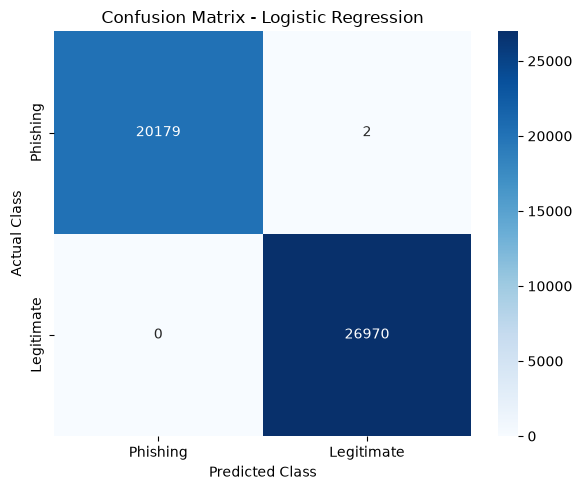


Decision Tree
[[20180     1]
 [    0 26970]]


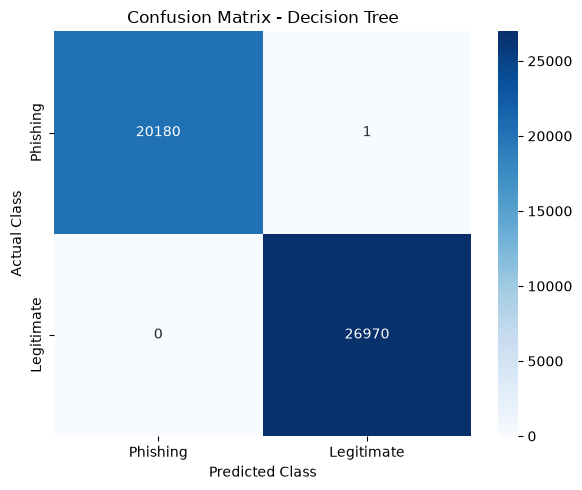


Random Forest
[[20180     1]
 [    0 26970]]


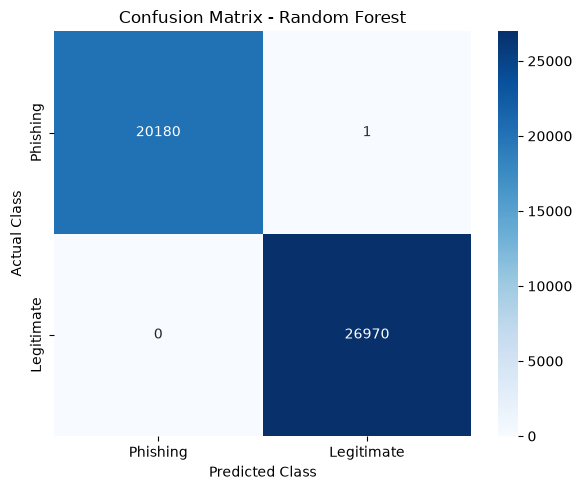


✅ Confusion matrices generated.


In [9]:
# Generate confusion matrices for all tuned models

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("CONFUSION MATRICES")
print("=" * 60)

for model_name in predictions:

    cm = confusion_matrix(
        y_test,
        predictions[model_name]
    )

    print(f"\n{model_name}")
    print(cm)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Phishing", "Legitimate"],
        yticklabels=["Phishing", "Legitimate"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

print("\n✅ Confusion matrices generated.")

In [10]:
# Generate detailed classification reports

from sklearn.metrics import classification_report

print("CLASSIFICATION REPORTS")
print("=" * 60)

for model_name in predictions:

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    report = classification_report(
        y_test,
        predictions[model_name],
        target_names=["Phishing", "Legitimate"],
        digits=4
    )

    print(report)

print("\n✅ Classification reports generated.")

CLASSIFICATION REPORTS

Logistic Regression
              precision    recall  f1-score   support

    Phishing     1.0000    0.9999    1.0000     20181
  Legitimate     0.9999    1.0000    1.0000     26970

    accuracy                         1.0000     47151
   macro avg     1.0000    1.0000    1.0000     47151
weighted avg     1.0000    1.0000    1.0000     47151


Decision Tree
              precision    recall  f1-score   support

    Phishing     1.0000    1.0000    1.0000     20181
  Legitimate     1.0000    1.0000    1.0000     26970

    accuracy                         1.0000     47151
   macro avg     1.0000    1.0000    1.0000     47151
weighted avg     1.0000    1.0000    1.0000     47151


Random Forest
              precision    recall  f1-score   support

    Phishing     1.0000    1.0000    1.0000     20181
  Legitimate     1.0000    1.0000    1.0000     26970

    accuracy                         1.0000     47151
   macro avg     1.0000    1.0000    1.0000     47151


ROC CURVE AND FINAL MODEL COMPARISON


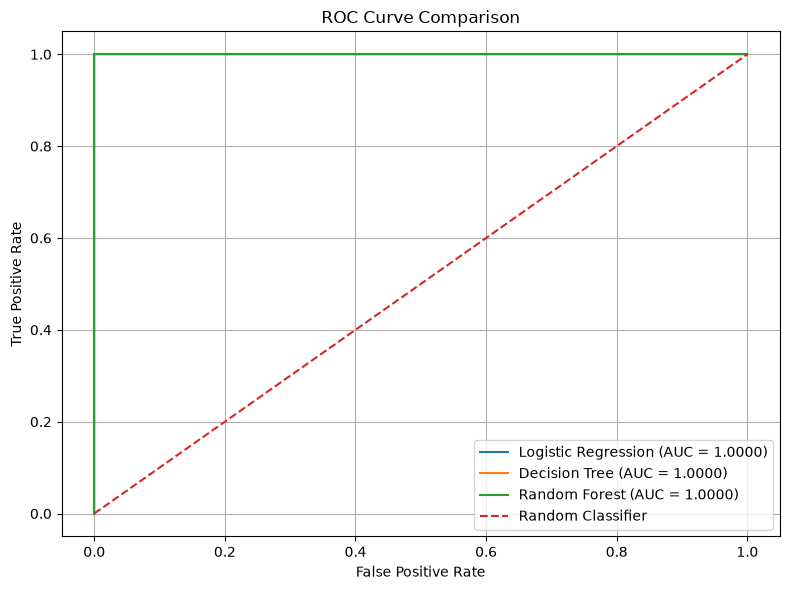


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,1.0,1.0000,1.0,1.0,1.0
1,Random Forest,1.0,1.0000,1.0,1.0,1.0
2,Logistic Regression,1.0,0.9999,1.0,1.0,1.0



Models evaluated: 3
Evaluation metrics: Accuracy, Precision, Recall, F1-Score, ROC-AUC

✅ MODEL EVALUATION AND COMPARISON COMPLETED


In [11]:
# Generate ROC curves and final model comparison

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

print("ROC CURVE AND FINAL MODEL COMPARISON")
print("=" * 60)

# Create ROC curve
plt.figure(figsize=(8, 6))

for model_name in probabilities:

    y_prob = probabilities[model_name]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Display final comparison table
print("\nFINAL MODEL COMPARISON")
print("=" * 60)

evaluation_df = evaluation_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(
    evaluation_df.round(4)
)

print("\nModels evaluated:", len(evaluation_df))
print("Evaluation metrics: Accuracy, Precision, Recall, F1-Score, ROC-AUC")

print("\n✅ MODEL EVALUATION AND COMPARISON COMPLETED")